<a href="https://colab.research.google.com/github/sonergunebakan1-netizen/cac-insight/blob/main/CAC_Insight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 CAC Insight — Analyse et notation financière automatisée du CAC 40

**Projet de groupe — Pairagogie, cours AI & Automation (M2 Analyse financière internationale)**

### Problématique métier
Comparer la santé financière de dizaines d'entreprises demande de récupérer les comptes à la main,
de calculer les ratios un par un, puis de rédiger une synthèse. **Comment automatiser ce travail
et aider un analyste à repérer en un coup d'œil les entreprises solides et fragiles ?**

### Ce que fait ce notebook
| Étape | Contenu | Brique technique |
|---|---|---|
| 1 | Collecte automatique des comptes annuels | API Yahoo Finance (`yfinance`) |
| 2 | Nettoyage et calcul des ratios | `pandas`, `numpy` |
| 3 | Exploration des données | `matplotlib`, `seaborn` |
| 4 | Regroupement des entreprises par profil | **Machine Learning** : K-Means (`scikit-learn`) |
| 5 | Notation bancaire de A à E | **Automatisation** : grille de scoring |
| 6 | Évaluation : score vs Machine Learning | Test de cohérence |
| 7 | Commentaire d'analyste pour chaque entreprise | **IA générative** : Gemini |
| 8 | Export du fichier qui alimente l'application | `cac40_scoring.csv` |

### Comment l'exécuter
1. Ajouter une clé API Gemini gratuite dans les **Secrets** de Colab (icône 🔑) sous le nom `GEMINI_API_KEY`
   (clé à créer sur aistudio.google.com).
2. Menu **Exécution → Tout exécuter**. Durée : environ 5 minutes, dont la génération des commentaires IA.

**Application en ligne :** *https://cac-insight-m2.streamlit.app/*

## Étape 0 — Installation et imports
On installe les bibliothèques qui ne sont pas fournies par défaut dans Colab, puis on importe tous les outils.

In [14]:
!pip install -q yfinance google-genai

import time
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_rows", 100)
print("✅ Environnement prêt")

✅ Environnement prêt


## Étape 1 — Collecte automatique des données

On récupère, pour chaque entreprise, les comptes du **dernier exercice annuel** via l'API Yahoo Finance.

**Périmètre :** sociétés du CAC 40 **hors banques, assurances et foncières**. Leurs bilans ont une structure
différente (les dépôts des clients sont des dettes, par exemple) : leurs ratios ne sont pas comparables
à ceux des entreprises industrielles.

**Point technique :** le nom d'une même ligne comptable varie selon les entreprises
(« Net Income » ou « Net Income Common Stockholders »). La fonction `get_value` essaie plusieurs noms
possibles pour chaque donnée.

*La composition du CAC 40 évolue chaque trimestre : vérifier la liste sur le site d'Euronext.*

In [15]:
tickers = {
    "AC.PA": "Accor", "AI.PA": "Air Liquide", "AIR.PA": "Airbus",
    "MT.AS": "ArcelorMittal", "EN.PA": "Bouygues", "BVI.PA": "Bureau Veritas",
    "CAP.PA": "Capgemini", "CA.PA": "Carrefour", "BN.PA": "Danone",
    "DSY.PA": "Dassault Systèmes", "EDEN.PA": "Edenred", "ENGI.PA": "Engie",
    "EL.PA": "EssilorLuxottica", "ERF.PA": "Eurofins", "RMS.PA": "Hermès",
    "KER.PA": "Kering", "OR.PA": "L'Oréal", "LR.PA": "Legrand",
    "MC.PA": "LVMH", "ML.PA": "Michelin", "ORA.PA": "Orange",
    "RI.PA": "Pernod Ricard", "PUB.PA": "Publicis", "RNO.PA": "Renault",
    "SAF.PA": "Safran", "SGO.PA": "Saint-Gobain", "SAN.PA": "Sanofi",
    "SU.PA": "Schneider Electric", "STLAP.PA": "Stellantis",
    "STMPA.PA": "STMicroelectronics", "HO.PA": "Thales",
    "TTE.PA": "TotalEnergies", "VIE.PA": "Veolia", "DG.PA": "Vinci",
}

def get_value(df, names, col=0):
    """Renvoie la première ligne disponible parmi plusieurs noms possibles."""
    for n in names:
        if n in df.index and df.shape[1] > col:
            v = df.loc[n].iloc[col]
            if pd.notna(v):
                return float(v)
    return np.nan

rows, erreurs = [], []
for ticker, nom in tickers.items():
    try:
        t = yf.Ticker(ticker)
        inc, bal = t.financials, t.balance_sheet
        rows.append({
            "Ticker": ticker,
            "Entreprise": nom,
            "Exercice": inc.columns[0].year,
            "CA": get_value(inc, ["Total Revenue"]),
            "CA_N-1": get_value(inc, ["Total Revenue"], col=1),
            "Resultat_net": get_value(inc, ["Net Income", "Net Income Common Stockholders"]),
            "EBIT": get_value(inc, ["EBIT", "Operating Income"]),
            "Charges_interets": get_value(inc, ["Interest Expense", "Interest Expense Non Operating"]),
            "Capitaux_propres": get_value(bal, ["Stockholders Equity", "Common Stock Equity"]),
            "Total_actif": get_value(bal, ["Total Assets"]),
            "Dette_totale": get_value(bal, ["Total Debt"]),
            "Actif_courant": get_value(bal, ["Current Assets"]),
            "Passif_courant": get_value(bal, ["Current Liabilities"]),
            "Capitalisation": t.fast_info.get("marketCap", np.nan),
        })
        print(f"✅ {nom}")
    except Exception as e:
        erreurs.append(nom)
        print(f"❌ {nom} : {e}")
    time.sleep(0.5)   # évite d'être bloqué par Yahoo

data = pd.DataFrame(rows)
data.to_csv("donnees_brutes.csv", index=False)
print(f"\n{len(data)} entreprises collectées, {len(erreurs)} erreur(s) : {erreurs}")
print("\nValeurs manquantes par colonne :")
print(data.isna().sum())

✅ Accor
✅ Air Liquide
✅ Airbus
✅ ArcelorMittal
✅ Bouygues
✅ Bureau Veritas
✅ Capgemini
✅ Carrefour
✅ Danone
✅ Dassault Systèmes
✅ Edenred
✅ Engie
✅ EssilorLuxottica
✅ Eurofins
✅ Hermès
✅ Kering
✅ L'Oréal
✅ Legrand
✅ LVMH
✅ Michelin
✅ Orange
✅ Pernod Ricard
✅ Publicis
✅ Renault
✅ Safran
✅ Saint-Gobain
✅ Sanofi
✅ Schneider Electric
✅ Stellantis
✅ STMicroelectronics
✅ Thales
✅ TotalEnergies
✅ Veolia
✅ Vinci

34 entreprises collectées, 0 erreur(s) : []

Valeurs manquantes par colonne :
Ticker              0
Entreprise          0
Exercice            0
CA                  0
CA_N-1              0
Resultat_net        0
EBIT                0
Charges_interets    1
Capitaux_propres    0
Total_actif         0
Dette_totale        0
Actif_courant       0
Passif_courant      0
Capitalisation      1
dtype: int64


## Étape 2 — Nettoyage et calcul des ratios

| Ratio | Formule | Ce qu'il mesure |
|---|---|---|
| Marge nette | Résultat net / CA | Rentabilité finale |
| Marge EBIT | EBIT / CA | Rentabilité opérationnelle |
| ROE | Résultat net / Capitaux propres | Rentabilité pour l'actionnaire |
| ROA | Résultat net / Total actif | Rentabilité des actifs |
| Gearing | Dette totale / Capitaux propres | Endettement |
| Liquidité générale | Actif courant / Passif courant | Capacité à payer à court terme |
| Couverture des intérêts | EBIT / Charges d'intérêts | Capacité à payer les intérêts |
| PER | Capitalisation / Résultat net | Valorisation boursière |
| Croissance du CA | CA N / CA N-1 − 1 | Dynamique commerciale |

**Choix de nettoyage (avec regard métier) :**
- **Devises** : ArcelorMittal et STMicroelectronics publient en dollars, leur capitalisation est en euros →
  conversion du résultat avant le calcul du PER.
- **Entreprises en perte** : un PER négatif n'a pas de sens → PER non significatif, information conservée
  dans la colonne `Perte`.
- **Capitaux propres négatifs** (cas d'Edenred) : un bénéfice divisé par des capitaux propres négatifs donne
  un ROE négatif trompeur. ROE neutralisé (médiane) et gearing fixé au maximum de l'échantillon,
  car l'entreprise est en réalité très endettée.
- **Valeurs manquantes** : remplacées par la médiane, plus robuste aux valeurs extrêmes que la moyenne.
  Avec 34 entreprises, on ne peut pas se permettre de supprimer des lignes.

In [16]:
df = data.copy()

# 1) Conversion de devise pour le PER
eurusd = yf.Ticker("EURUSD=X").fast_info["lastPrice"]
usd = df["Ticker"].isin(["MT.AS", "STMPA.PA"])
df["Resultat_net_EUR"] = np.where(usd, df["Resultat_net"] / eurusd, df["Resultat_net"])

# 2) Calcul des ratios
df["Marge_nette"]    = df["Resultat_net"] / df["CA"]
df["Marge_EBIT"]     = df["EBIT"] / df["CA"]
df["ROE"]            = df["Resultat_net"] / df["Capitaux_propres"]
df["ROA"]            = df["Resultat_net"] / df["Total_actif"]
df["Gearing"]        = df["Dette_totale"] / df["Capitaux_propres"]
df["Liquidite"]      = df["Actif_courant"] / df["Passif_courant"]
df["Couverture_int"] = df["EBIT"] / df["Charges_interets"].abs().replace(0, np.nan)
df["PER"]            = df["Capitalisation"] / df["Resultat_net_EUR"]
df["Croissance_CA"]  = df["CA"] / df["CA_N-1"] - 1

ratios = ["Marge_nette", "Marge_EBIT", "ROE", "ROA", "Gearing",
          "Liquidite", "Couverture_int", "PER", "Croissance_CA"]

# 3) Entreprises en perte : PER non significatif
df["Perte"] = df["Resultat_net"] < 0
df.loc[df["Perte"], "PER"] = np.nan

# 4) Capitaux propres négatifs : ROE et gearing non interprétables
cp_neg = df["Capitaux_propres"] < 0
df.loc[cp_neg, "ROE"] = df.loc[~cp_neg, "ROE"].median()
df.loc[cp_neg, "Gearing"] = df.loc[~cp_neg, "Gearing"].max()

# 5) Valeurs manquantes -> médiane
print("Valeurs manquantes traitées :", df[ratios].isna().sum().sum())
for r in ratios:
    df[r] = df[r].fillna(df[r].median())

print(f"Taux EUR/USD utilisé : {eurusd:.4f}")
print("Entreprises en perte :", list(df.loc[df["Perte"], "Entreprise"]))
print("Capitaux propres négatifs :", list(df.loc[cp_neg, "Entreprise"]))

affichage = df[["Entreprise"] + ratios].set_index("Entreprise").copy()
pct = ["Marge_nette", "Marge_EBIT", "ROE", "ROA", "Croissance_CA"]
affichage[pct] = affichage[pct] * 100
affichage.round(2).sort_values("ROE", ascending=False)

Valeurs manquantes traitées : 4
Taux EUR/USD utilisé : 1.1183
Entreprises en perte : ['Renault', 'Stellantis']
Capitaux propres négatifs : ['Edenred']


,Marge_nette,Marge_EBIT,ROE,ROA,Gearing,Liquidite,Couverture_int,PER,Croissance_CA
Entreprise,,,,,,,,,
Safran,23.01,33.36,48.37,11.61,0.36,0.93,77.07,15.90,12.53
Bureau Veritas,9.09,15.01,34.37,8.32,1.80,1.53,10.18,22.04,3.61
Hermès,28.27,42.68,24.01,18.60,0.12,4.99,124.18,29.95,5.48
Thales,7.56,10.50,21.01,4.28,0.77,0.84,8.07,28.94,7.58
Airbus,7.11,9.70,20.00,3.87,0.42,1.16,9.25,29.17,6.05
L'Oréal,13.91,20.15,17.53,9.91,0.34,1.44,23.68,38.03,1.30
Schneider Electric,10.37,16.74,17.20,6.66,0.74,1.19,12.44,33.55,5.24
Legrand,13.13,19.61,17.06,7.07,0.91,1.93,11.07,27.59,9.62
LVMH,13.46,22.09,16.12,7.66,0.54,1.58,15.51,17.54,-4.58


## Étape 3 — Exploration des données

- **Statistiques descriptives** : repérer les valeurs extrêmes.
- **Matrice de corrélations** : identifier les ratios qui disent la même chose. Marge nette, marge EBIT et ROA
  sont très corrélés (0,90 à 0,97) : on n'en gardera qu'un pour le Machine Learning, sinon la rentabilité
  compterait triple.
- **Rentabilité vs endettement** et **classement par ROE** : une première intuition des profils.

,Marge_nette,Marge_EBIT,ROE,ROA,Gearing,Liquidite,Couverture_int,PER,Croissance_CA
count,34.00,34.00,34.00,34.00,34.00,34.00,34.00,34.00,34.00
mean,0.08,0.13,0.10,0.04,0.88,1.40,14.23,38.52,0.01
std,0.09,0.11,0.17,0.05,0.76,0.83,26.24,61.98,0.06
min,-0.19,-0.17,-0.53,-0.11,0.12,0.84,-25.01,10.55,-0.14
25%,0.05,0.09,0.08,0.03,0.37,0.97,5.05,14.53,-0.01
50%,0.07,0.12,0.11,0.04,0.73,1.11,8.07,23.12,0.01
75%,0.13,0.18,0.16,0.07,1.00,1.51,11.76,29.75,0.05
max,0.28,0.43,0.48,0.19,3.32,4.99,124.18,302.22,0.13


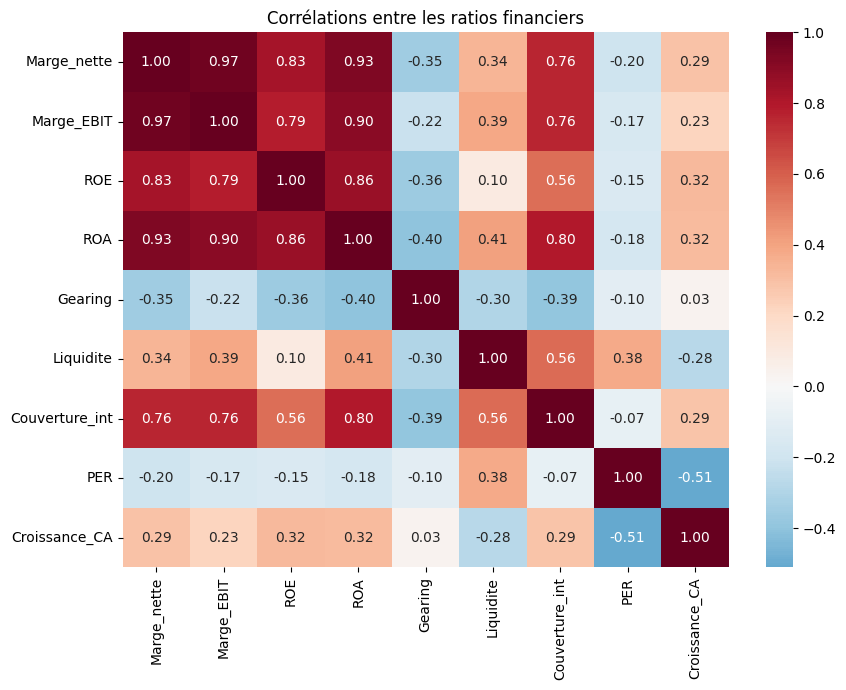

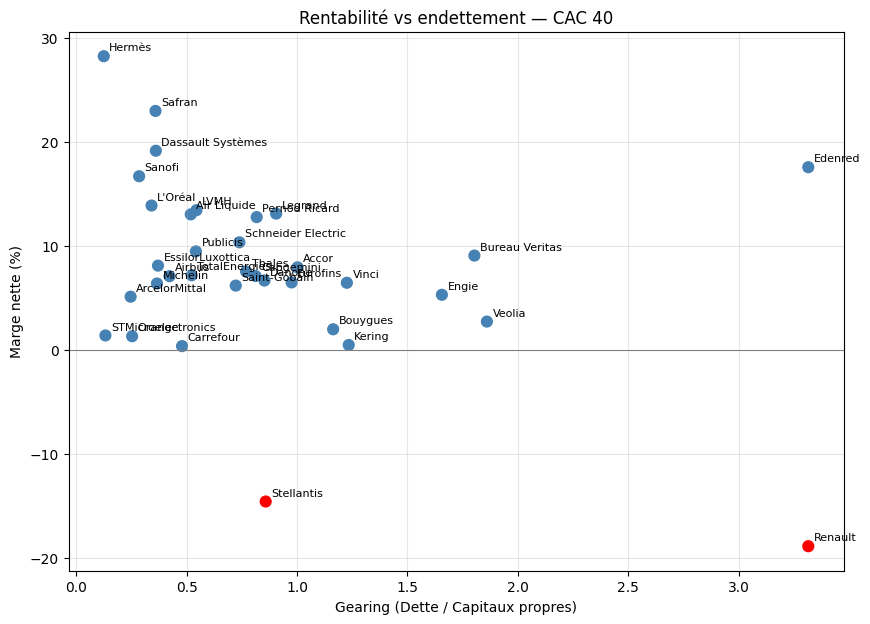

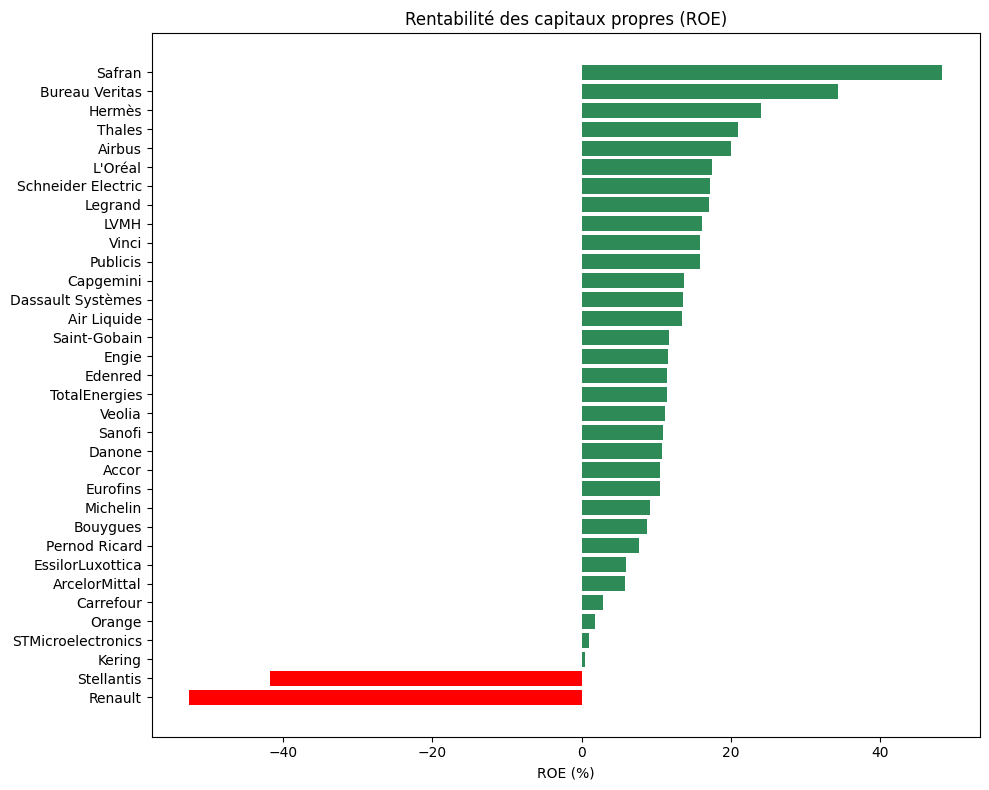

In [17]:
display(df[ratios].describe().round(2))

plt.figure(figsize=(9, 7))
sns.heatmap(df[ratios].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Corrélations entre les ratios financiers")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 7))
plt.scatter(df["Gearing"], df["Marge_nette"] * 100,
            c=np.where(df["Perte"], "red", "steelblue"), s=60)
for _, row in df.iterrows():
    plt.annotate(row["Entreprise"], (row["Gearing"], row["Marge_nette"] * 100),
                 fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.axhline(0, color="grey", lw=0.8)
plt.xlabel("Gearing (Dette / Capitaux propres)"); plt.ylabel("Marge nette (%)")
plt.title("Rentabilité vs endettement — CAC 40"); plt.grid(alpha=0.3); plt.show()

top = df.sort_values("ROE")
plt.figure(figsize=(10, 8))
plt.barh(top["Entreprise"], top["ROE"] * 100, color=np.where(top["ROE"] < 0, "red", "seagreen"))
plt.xlabel("ROE (%)"); plt.title("Rentabilité des capitaux propres (ROE)")
plt.tight_layout(); plt.show()

## Étape 4 — Machine Learning : regroupement par profil (K-Means)

**Le principe :** le K-Means regroupe automatiquement les entreprises qui se ressemblent, sans qu'on lui dise
à l'avance quels groupes chercher (apprentissage **non supervisé**).

**Les 6 variables retenues**, complémentaires et peu corrélées :
Marge EBIT (rentabilité opérationnelle), ROE (rentabilité actionnaire), Gearing (solvabilité),
Liquidité, PER (valorisation), Croissance du CA (dynamique).

**Préparation :**
- **Écrêtage** au 5e et 95e percentile : le K-Means est sensible aux valeurs extrêmes (un PER de 300
  tirerait tout le modèle).
- **Standardisation** : met tous les ratios sur la même échelle, sinon le PER (≈ 20) écraserait la marge (≈ 0,1).

**Choix du nombre de groupes :** score de silhouette (qualité de séparation des groupes) et méthode du coude.
On retient le meilleur score entre 3 et 6 groupes : 2 groupes seraient trop grossiers pour un analyste.

**Nommage des groupes :** automatique, à partir de leur profil médian (le plus grand groupe = « Socle solide »,
celui des entreprises en perte = « En difficulté », etc.). À vérifier si les données changent.

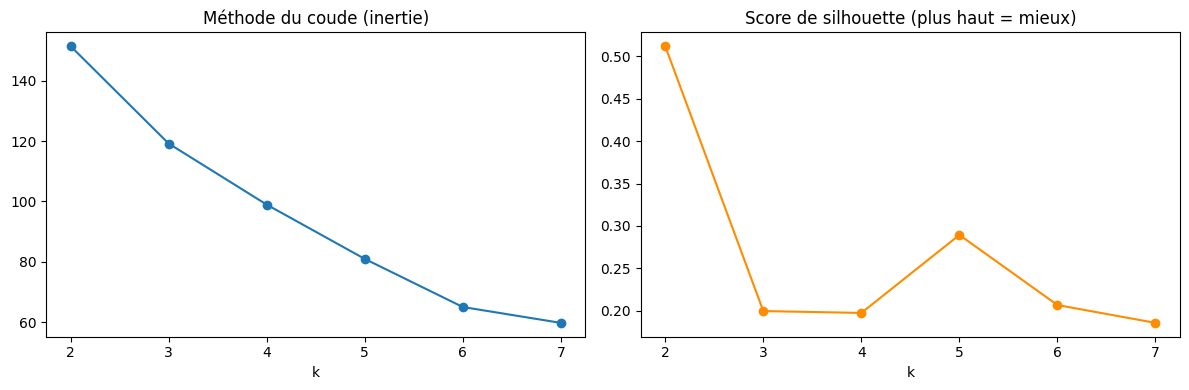

k = 2 : silhouette = 0.512
k = 3 : silhouette = 0.200
k = 4 : silhouette = 0.197
k = 5 : silhouette = 0.289
k = 6 : silhouette = 0.207
k = 7 : silhouette = 0.186

→ Nombre de groupes retenu : 5


In [18]:
features = ["Marge_EBIT", "ROE", "Gearing", "Liquidite", "PER", "Croissance_CA"]

X = df[features].copy()
for f in features:
    X[f] = X[f].clip(X[f].quantile(0.05), X[f].quantile(0.95))
X_scaled = StandardScaler().fit_transform(X)

# Choix du nombre de groupes
scores, inerties = {}, []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    scores[k] = silhouette_score(X_scaled, km.labels_)
    inerties.append(km.inertia_)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 8), inerties, "o-"); ax[0].set_title("Méthode du coude (inertie)"); ax[0].set_xlabel("k")
ax[1].plot(list(scores), list(scores.values()), "o-", color="darkorange")
ax[1].set_title("Score de silhouette (plus haut = mieux)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
for k, s in scores.items():
    print(f"k = {k} : silhouette = {s:.3f}")

k_opt = max(range(3, 7), key=lambda k: scores[k])
print(f"\n→ Nombre de groupes retenu : {k_opt}")

kmeans = KMeans(n_clusters=k_opt, n_init=10, random_state=42).fit(X_scaled)
df["Cluster"] = kmeans.labels_

In [19]:
# Nommage automatique des groupes à partir de leur profil médian
prof = df.groupby("Cluster").agg(n=("Entreprise", "size"), part_perte=("Perte", "mean"),
                                 **{f: (f, "median") for f in features})
noms_profils, restants = {}, list(prof.index)

def attribuer(nom, c):
    noms_profils[c] = nom
    restants.remove(c)

attribuer("Socle solide", prof.loc[restants, "n"].idxmax())
en_perte = prof.loc[restants][prof.loc[restants, "part_perte"] >= 0.5]
if len(en_perte):
    attribuer("En difficulté", en_perte["Marge_EBIT"].idxmin())
for nom, col, sens in [("Fortement endetté", "Gearing", "max"),
                       ("Forte liquidité", "Liquidite", "max"),
                       ("Rentabilité en berne", "ROE", "min")]:
    if restants:
        s = prof.loc[restants, col]
        attribuer(nom, s.idxmax() if sens == "max" else s.idxmin())
for c in list(restants):
    attribuer(f"Profil {c}", c)

df["Profil"] = df["Cluster"].map(noms_profils)

profil = df.groupby("Profil")[features].median()
profil[["Marge_EBIT", "ROE", "Croissance_CA"]] *= 100
profil["Nb_entreprises"] = df["Profil"].value_counts()
print("Profil médian par groupe (marges, ROE et croissance en %) :")
display(profil.round(2))
for p in profil.index:
    print(f"{p} : {', '.join(df.loc[df['Profil'] == p, 'Entreprise'])}")

Profil médian par groupe (marges, ROE et croissance en %) :


,Marge_EBIT,ROE,Gearing,Liquidite,PER,Croissance_CA,Nb_entreprises
Profil,,,,,,,
En difficulté,-16.71,-47.17,2.09,1.02,23.12,0.43,2
Forte liquidité,33.12,15.89,0.47,3.73,22.06,-4.36,2
Fortement endetté,13.69,11.52,1.83,0.97,17.84,1.48,4
Rentabilité en berne,5.59,0.71,0.68,2.68,277.28,-12.05,2
Socle solide,12.40,12.58,0.53,1.11,23.39,0.99,24


En difficulté : Renault, Stellantis
Forte liquidité : Hermès, Pernod Ricard
Fortement endetté : Bureau Veritas, Edenred, Engie, Veolia
Rentabilité en berne : Kering, STMicroelectronics
Socle solide : Accor, Air Liquide, Airbus, ArcelorMittal, Bouygues, Capgemini, Carrefour, Danone, Dassault Systèmes, EssilorLuxottica, Eurofins, L'Oréal, Legrand, LVMH, Michelin, Orange, Publicis, Safran, Saint-Gobain, Sanofi, Schneider Electric, Thales, TotalEnergies, Vinci


### Visualisation des groupes (ACP)

On ne peut pas dessiner 6 dimensions. L'**Analyse en Composantes Principales (ACP)** les résume en **2 axes**
en gardant le maximum d'information, comme une photo d'un objet en 3D.
**Chaque point est une entreprise ; deux points proches ont des profils financiers proches ;
la couleur est le groupe trouvé par le K-Means.** Les axes n'ont pas d'unité : seules les distances comptent.

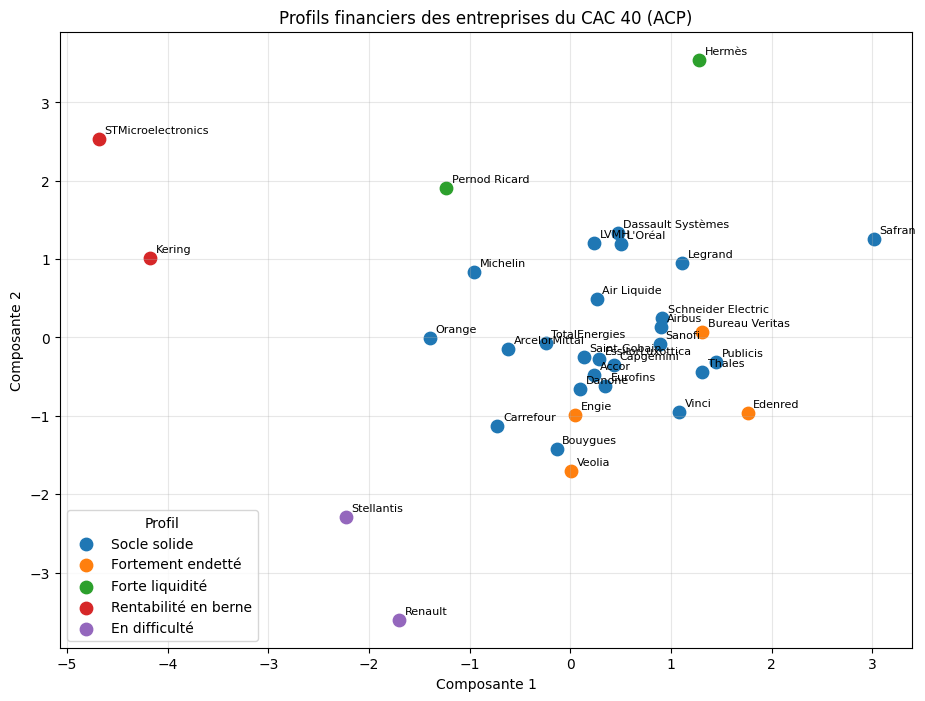

In [20]:
coords = PCA(n_components=2).fit_transform(X_scaled)
plt.figure(figsize=(11, 8))
for p in df["Profil"].unique():
    m = (df["Profil"] == p).values
    plt.scatter(coords[m, 0], coords[m, 1], s=80, label=p)
for i, nom in enumerate(df["Entreprise"]):
    plt.annotate(nom, coords[i], fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.legend(title="Profil")
plt.title("Profils financiers des entreprises du CAC 40 (ACP)")
plt.xlabel("Composante 1"); plt.ylabel("Composante 2"); plt.grid(alpha=0.3); plt.show()

## Étape 5 — Notation bancaire (scoring de A à E)

Grille inspirée des scorecards de risque de crédit. Chaque ratio rapporte des points par paliers ;
le total est sur 100.

| Pilier | Ratio | Points max |
|---|---|---|
| Rentabilité | Marge EBIT | 20 |
| | ROE | 15 |
| Solvabilité | Gearing (capitaux propres négatifs = 0) | 20 |
| | Couverture des intérêts | 15 |
| Liquidité | Liquidité générale | 15 |
| Dynamique | Croissance du CA | 15 |

**Notes :** A ≥ 80 Excellent · B ≥ 65 Solide · C ≥ 50 Correct · D ≥ 35 Fragile · E < 35 Risqué

Le **PER est exclu du score** : une banque évalue la capacité à rembourser, pas la valorisation boursière.

,Entreprise,Score,Note,Appreciation,Profil
0,Hermès,96,A,Excellent,Forte liquidité
1,Dassault Systèmes,88,A,Excellent,Socle solide
2,L'Oréal,88,A,Excellent,Socle solide
3,Safran,88,A,Excellent,Socle solide
4,Legrand,86,A,Excellent,Socle solide
5,LVMH,83,A,Excellent,Socle solide
6,Sanofi,75,B,Solide,Socle solide
7,Schneider Electric,74,B,Solide,Socle solide
8,Publicis,74,B,Solide,Socle solide
9,Airbus,74,B,Solide,Socle solide


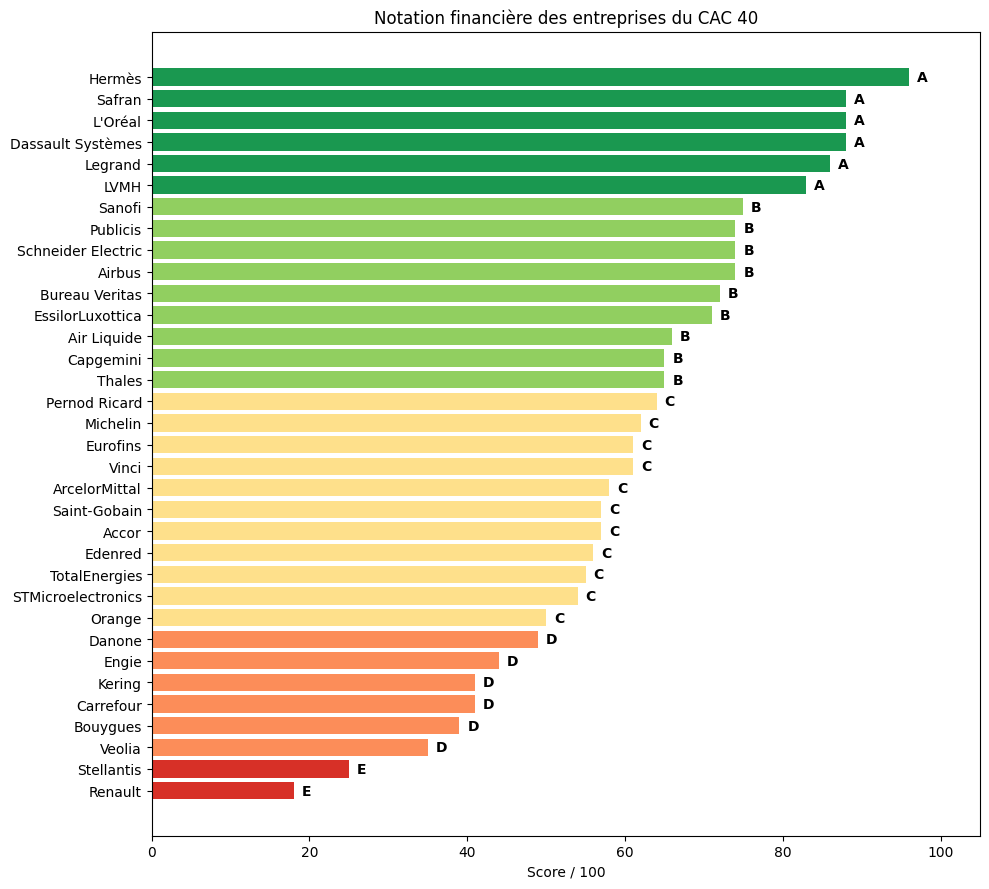

In [21]:
def pts_haut(v, seuils, points):
    """Plus la valeur est haute, mieux c'est."""
    for s, p in zip(seuils, points):
        if v >= s:
            return p
    return 0

def pts_bas(v, seuils, points):
    """Plus la valeur est basse, mieux c'est (endettement)."""
    for s, p in zip(seuils, points):
        if v <= s:
            return p
    return 0

def scorer(row):
    s = {}
    s["Pts_Marge_EBIT"] = pts_haut(row["Marge_EBIT"], [0.20, 0.12, 0.06, 0.0], [20, 15, 10, 5])
    s["Pts_ROE"]        = pts_haut(row["ROE"], [0.15, 0.10, 0.05, 0.0], [15, 11, 7, 3])
    s["Pts_Gearing"]    = 0 if row["Capitaux_propres"] < 0 else \
                          pts_bas(row["Gearing"], [0.5, 1.0, 1.5, 2.5], [20, 15, 10, 5])
    s["Pts_Couverture"] = pts_haut(row["Couverture_int"], [15, 8, 4, 1.5], [15, 11, 7, 3])
    s["Pts_Liquidite"]  = pts_haut(row["Liquidite"], [1.5, 1.2, 1.0, 0.8], [15, 11, 7, 3])
    s["Pts_Croissance"] = pts_haut(row["Croissance_CA"], [0.08, 0.03, 0.0, -0.05], [15, 11, 7, 3])
    s["Score"] = sum(s.values())
    return pd.Series(s)

def note(score):
    for seuil, n in [(80, "A"), (65, "B"), (50, "C"), (35, "D")]:
        if score >= seuil:
            return n
    return "E"

df = pd.concat([df, df.apply(scorer, axis=1)], axis=1)
df["Note"] = df["Score"].apply(note)
df["Appreciation"] = df["Note"].map({"A": "Excellent", "B": "Solide", "C": "Correct",
                                     "D": "Fragile", "E": "Risqué"})

resultat = df[["Entreprise", "Score", "Note", "Appreciation", "Profil"]] \
             .sort_values("Score", ascending=False).reset_index(drop=True)
display(resultat)

couleurs = {"A": "#1a9850", "B": "#91cf60", "C": "#fee08b", "D": "#fc8d59", "E": "#d73027"}
r = resultat.sort_values("Score")
plt.figure(figsize=(10, 9))
plt.barh(r["Entreprise"], r["Score"], color=r["Note"].map(couleurs))
for i, (sc, nt) in enumerate(zip(r["Score"], r["Note"])):
    plt.text(sc + 1, i, nt, va="center", fontweight="bold")
plt.xlim(0, 105); plt.xlabel("Score / 100")
plt.title("Notation financière des entreprises du CAC 40")
plt.tight_layout(); plt.show()

## Étape 6 — Évaluation : le score et le Machine Learning concordent-ils ?

Le scoring (règles bancaires) et le K-Means (algorithme) sont **deux approches indépendantes**.
Si elles aboutissent aux mêmes conclusions, cela valide la démarche.

**À lire dans le tableau :**
- Les entreprises « En difficulté » doivent avoir les notes les plus basses (E).
- Un écart (ex : profil « Fortement endetté » mais note B) n'est pas une erreur : il montre que les deux
  approches sont **complémentaires** (une forte rentabilité peut compenser une dette élevée).
- Limite : le K-Means regroupe des **formes** de profil, pas des **niveaux** de santé ; un grand groupe
  peut donc contenir des notes variées.

In [22]:
display(pd.crosstab(df["Profil"], df["Note"]))

Note,A,B,C,D,E
Profil,,,,,
En difficulté,0,0,0,0,2
Forte liquidité,1,0,1,0,0
Fortement endetté,0,1,1,2,0
Rentabilité en berne,0,0,1,1,0
Socle solide,5,8,8,3,0


## Étape 7 — IA générative : commentaire d'analyste pour chaque entreprise

Un modèle Gemini rédige 4 phrases par entreprise : appréciation globale, point fort, point de vigilance.

**Garde-fous :**
- **Anti-hallucination** : le modèle reçoit uniquement les chiffres calculés, avec la consigne de ne rien inventer.
- **Robustesse** : si un modèle est saturé, on passe automatiquement au suivant (rotation), avec plusieurs essais.
- **Indépendance de l'application** : les commentaires sont générés une seule fois ici et enregistrés dans
  le fichier ; l'application ne dépend pas de la disponibilité de l'API.
- **Sécurité** : la clé API est stockée dans les Secrets de Colab, jamais dans le code.

*Les fournisseurs remplacent régulièrement leurs modèles : mettre à jour la liste `MODELES` si besoin
(`client.models.list()` affiche les modèles disponibles).*

In [23]:
from google import genai
from google.colab import userdata

try:
    client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
    print("✅ Clé Gemini trouvée")
except Exception:
    client = None
    print("⚠️ Pas de clé GEMINI_API_KEY : les commentaires IA seront ignorés, le reste du notebook fonctionne.")
MODELES = ["gemini-3.5-flash-lite", "gemini-flash-lite-latest", "gemini-3.7-flash", "gemini-3.8-flash"]
ECHEC = "Commentaire indisponible."
med = df[ratios].median()

def prompt(row):
    return f"""Tu es analyste crédit dans une banque. Rédige un commentaire de 4 phrases maximum,
en français, clair et professionnel, sur la santé financière de {row['Entreprise']}.

Utilise UNIQUEMENT les chiffres ci-dessous. N'invente aucune information extérieure
(actualité, stratégie, chiffres non fournis).

- Note : {row['Note']} ({row['Appreciation']}), score {row['Score']}/100
- Profil de groupe : {row['Profil']}
- Marge EBIT : {row['Marge_EBIT']:.1%} (médiane CAC 40 : {med['Marge_EBIT']:.1%})
- ROE : {row['ROE']:.1%} (médiane : {med['ROE']:.1%})
- Gearing : {row['Gearing']:.2f} (médiane : {med['Gearing']:.2f}){' — capitaux propres négatifs' if row['Capitaux_propres'] < 0 else ''}
- Couverture des intérêts : {row['Couverture_int']:.1f}x (médiane : {med['Couverture_int']:.1f}x)
- Liquidité générale : {row['Liquidite']:.2f} (médiane : {med['Liquidite']:.2f})
- Croissance du CA : {row['Croissance_CA']:.1%}
- Entreprise en perte : {'oui' if row['Perte'] else 'non'}

Structure : 1) appréciation globale, 2) point fort principal, 3) point de vigilance principal."""

if "Commentaire" not in df.columns:
    df["Commentaire"] = ECHEC

✅ Clé Gemini trouvée


In [24]:
# Génération (relançable : ne traite que les commentaires manquants)
a_faire = [] if client is None else df.index[df["Commentaire"].isna() | (df["Commentaire"] == ECHEC)]
print(f"{len(a_faire)} commentaire(s) à générer\n")

for i in a_faire:
    row = df.loc[i]
    reussi = False
    for tour in range(3):
        for modele in MODELES:
            try:
                rep = client.models.generate_content(model=modele, contents=prompt(row))
                df.at[i, "Commentaire"] = rep.text.strip()
                print(f"✅ {row['Entreprise']}  ({modele})")
                reussi = True
                break
            except Exception:
                continue
        if reussi:
            break
        print(f"⏳ {row['Entreprise']} : modèles occupés, pause de 20 s")
        time.sleep(20)
    if not reussi:
        print(f"❌ {row['Entreprise']} : abandon pour l'instant (relancer la cellule plus tard)")
    time.sleep(3)

print(f"\nCommentaires manquants : {(df['Commentaire'] == ECHEC).sum()}")

for nom in ["Hermès", "Renault", "Bureau Veritas"]:
    if nom in df["Entreprise"].values:
        print(f"\n=== {nom} ===")
        print(df.loc[df["Entreprise"] == nom, "Commentaire"].values[0])

34 commentaire(s) à générer

✅ Accor  (gemini-3.5-flash-lite)
✅ Air Liquide  (gemini-3.5-flash-lite)
✅ Airbus  (gemini-3.5-flash-lite)
✅ ArcelorMittal  (gemini-3.5-flash-lite)
✅ Bouygues  (gemini-3.5-flash-lite)
✅ Bureau Veritas  (gemini-3.5-flash-lite)
✅ Capgemini  (gemini-3.5-flash-lite)
✅ Carrefour  (gemini-3.5-flash-lite)
✅ Danone  (gemini-3.5-flash-lite)
✅ Dassault Systèmes  (gemini-3.5-flash-lite)
✅ Edenred  (gemini-3.5-flash-lite)
✅ Engie  (gemini-3.5-flash-lite)
✅ EssilorLuxottica  (gemini-3.5-flash-lite)
✅ Eurofins  (gemini-3.5-flash-lite)
✅ Hermès  (gemini-3.5-flash-lite)
✅ Kering  (gemini-3.5-flash-lite)
✅ L'Oréal  (gemini-3.5-flash-lite)
✅ Legrand  (gemini-3.5-flash-lite)
✅ LVMH  (gemini-3.5-flash-lite)
✅ Michelin  (gemini-3.5-flash-lite)
✅ Orange  (gemini-3.5-flash-lite)
✅ Pernod Ricard  (gemini-3.5-flash-lite)
✅ Publicis  (gemini-3.5-flash-lite)
✅ Renault  (gemini-3.5-flash-lite)
✅ Safran  (gemini-3.5-flash-lite)
✅ Saint-Gobain  (gemini-3.5-flash-lite)
✅ Sanofi  (gemini-3

## Étape 8 — Export pour l'application

Le fichier `cac40_scoring.csv` contient tout ce que l'application affiche : ratios, points, score, note,
profil et commentaire. Il suffit de le déposer sur GitHub pour mettre l'application à jour.

In [25]:
df.to_csv("cac40_scoring.csv", index=False)
print(f"✅ cac40_scoring.csv sauvegardé ({len(df)} entreprises, {df.shape[1]} colonnes)")

try:
    from google.colab import files
    files.download("cac40_scoring.csv")
except Exception:
    pass

✅ cac40_scoring.csv sauvegardé (34 entreprises, 37 colonnes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limites et pistes d'amélioration

**Limites**
- **Données** : Yahoo Finance peut contenir des imprécisions ; un ratio atypique (ex : ROE de Safran)
  doit être vérifié dans le rapport annuel.
- **Échantillon réduit** : 34 entreprises, une seule année.
- **Grille unique** pour tous les secteurs, alors que les normes diffèrent (luxe vs services aux collectivités).
- **K-Means** : décrit des profils, ne prédit rien ; un groupe « Socle solide » large et hétérogène.
- **IA générative** : peut mal interpréter un chiffre → relecture humaine ; commentaires issus de deux modèles,
  style légèrement variable.
- **Dépendance à des API externes** (Yahoo, Gemini) dont les modèles et formats évoluent.

**Pistes d'amélioration**
- Étendre à l'Euro Stoxx 50 et suivre l'évolution sur plusieurs années.
- Adapter les seuils de la grille par secteur.
- Ajouter un modèle supervisé de probabilité de défaut.
- Automatiser la mise à jour annuelle avec une tâche planifiée (GitHub Actions).